# 01: Network Demand Patterns
**Milestone 2: Week 3 — Steps 1 to 3**

This notebook explores macro-level ridership patterns across the entire Manhattan bus network (41 routes):
- **Step 1:** Define which days count as 'typical' (reusable filter).
- **Step 3:** Network patterns:
  1. Daily riders over the study window (with timetable switchover vertical lines and disruption shading)
  2. Average riders by hour for typical weekdays, Saturdays, and Sundays (with middle 50% IQR band)
  3. Weekday riders by month (summer dip & September rebound)
  4. The 10 busiest network hours on typical weekdays

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.eda_utils import typical_days, DAY_TYPE_COLORS, calc_period_ratio, calc_cv

DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

matched = pd.read_parquet(DATA / "matched_hourly.parquet")
profiles = pd.read_parquet(DATA / "route_profiles.parquet")
print(f"Loaded matched hourly: {len(matched):,} rows (41 routes)")
print(f"Loaded route profiles: {len(profiles)} routes")


Loaded matched hourly: 233,227 rows (41 routes)
Loaded route profiles: 41 routes


## Step 1: Define 'Typical' Days Filter
Normal travel days exclude public holidays, special holiday timetables, storm disruptions, and data outage hours.
We inspect the date distribution across typical weekdays, Saturdays, Sundays, and special dates.

In [2]:
wd_typical = typical_days(matched, 'weekday')
sat_typical = typical_days(matched, 'saturday')
sun_typical = typical_days(matched, 'sunday')

print(f'Typical Weekdays:  {wd_typical["date"].nunique():>3} dates ({len(wd_typical):>6,} route-hours)')
print(f'Typical Saturdays: {sat_typical["date"].nunique():>3} dates ({len(sat_typical):>6,} route-hours)')
print(f'Typical Sundays:   {sun_typical["date"].nunique():>3} dates ({len(sun_typical):>6,} route-hours)')

# Verify special/disrupted dates
special_mask = (matched['is_public_holiday']) | (matched['holiday_schedule']) | (matched['is_storm'])
special_dates = matched[special_mask][['date', 'day_of_week', 'is_public_holiday', 'holiday_schedule', 'is_storm']].drop_duplicates()
print(f'\nSpecial Dates ({len(special_dates)} days):')
special_dates.head(15)

Typical Weekdays:  180 dates (161,233 route-hours)
Typical Saturdays:  36 dates (31,007 route-hours)
Typical Sundays:    36 dates (30,557 route-hours)

Special Dates (12 days):


,date,day_of_week,is_public_holiday,holiday_schedule,is_storm
201,2026-01-19,Monday,True,True,False
336,2026-01-25,Sunday,False,False,True
359,2026-01-26,Monday,False,False,True
842,2026-02-16,Monday,True,True,False
979,2026-02-22,Sunday,False,False,True
1002,2026-02-23,Monday,False,False,True
1025,2026-02-24,Tuesday,False,False,True
3070,2026-05-25,Monday,True,True,False
3643,2026-06-19,Friday,True,False,False
3961,2026-07-03,Friday,True,True,False


## Step 3.1: Daily Network Ridership Over Whole Window
Daily network boardings plotted with timetable version switchover lines and disruption shading.

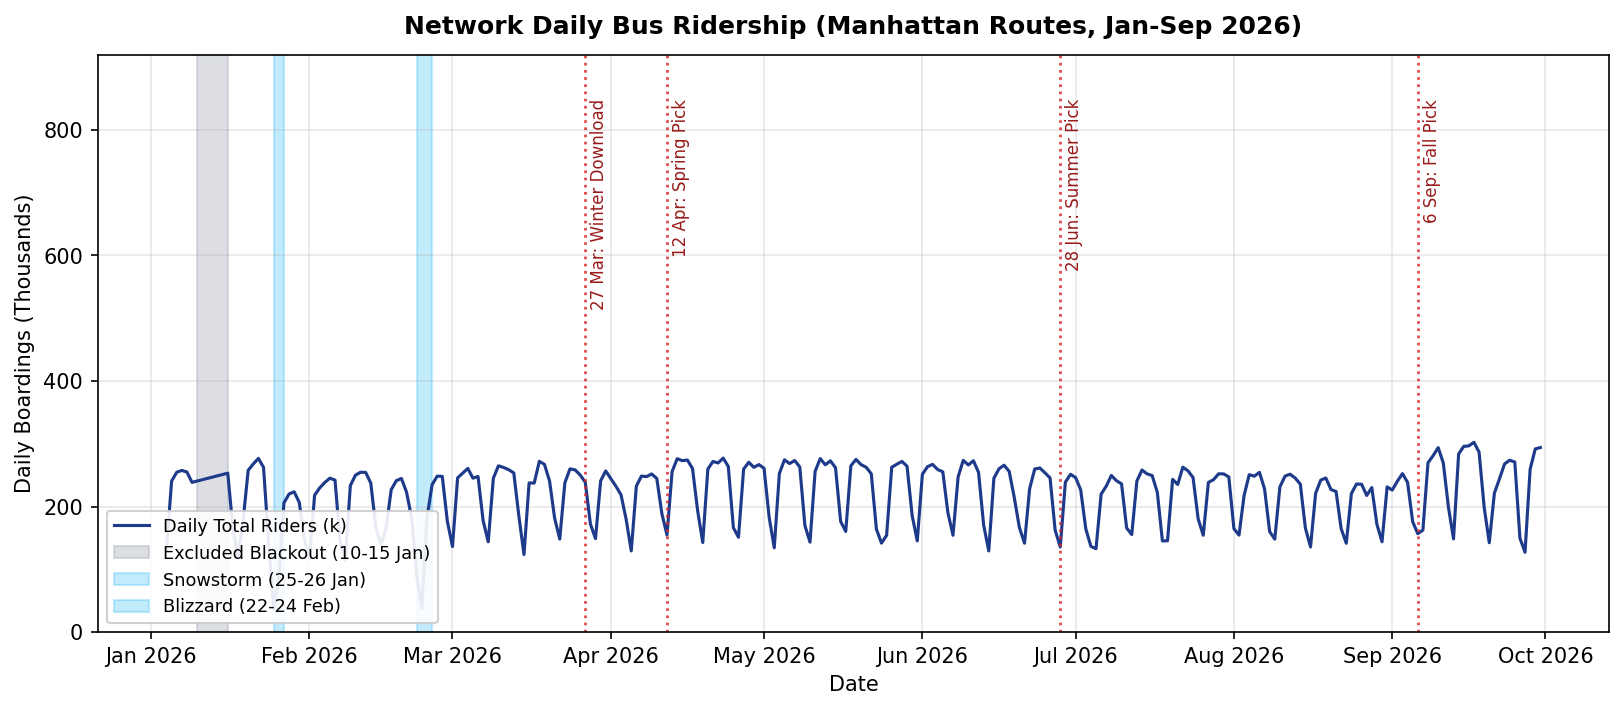

In [3]:
import matplotlib.dates as mdates

daily = matched.groupby('date')['ridership'].sum().reset_index()
daily['dt'] = pd.to_datetime(daily['date'])
daily = daily.sort_values('dt')

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
ax.plot(daily['dt'], daily['ridership'] / 1000.0, color='#1e3a8a', linewidth=1.5, label='Daily Total Riders (k)')

# Timetable switchover lines
switchovers = [
    ('2026-03-27', '27 Mar: Winter Download'),
    ('2026-04-12', '12 Apr: Spring Pick'),
    ('2026-06-28', '28 Jun: Summer Pick'),
    ('2026-09-06', '6 Sep: Fall Pick'),
]
for d_str, lbl in switchovers:
    dt = pd.to_datetime(d_str)
    ax.axvline(dt, color='#dc2626', linestyle=':', linewidth=1.3, alpha=0.85)
    ax.text(dt + pd.Timedelta(days=1), 850, lbl, rotation=90, fontsize=8, color='#991b1b', verticalalignment='top')

# Disruption shading
ax.axvspan(pd.to_datetime('2026-01-10'), pd.to_datetime('2026-01-16'), color='#9ca3af', alpha=0.35, label='Excluded Blackout (10-15 Jan)')
ax.axvspan(pd.to_datetime('2026-01-25'), pd.to_datetime('2026-01-27'), color='#38bdf8', alpha=0.3, label='Snowstorm (25-26 Jan)')
ax.axvspan(pd.to_datetime('2026-02-22'), pd.to_datetime('2026-02-25'), color='#38bdf8', alpha=0.3, label='Blizzard (22-24 Feb)')

ax.set_title('Network Daily Bus Ridership (Manhattan Routes, Jan-Sep 2026)', fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('Daily Boardings (Thousands)', fontsize=10)
ax.set_xlabel('Date', fontsize=10)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_ylim(0, 920)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', framealpha=0.9, fontsize=8.5)
fig.savefig(FIG / 'm2_network_daily_ridership.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 3.2: Average Riders by Hour with Middle 50% Band (IQR)
For typical weekdays, Saturdays, and Sundays, we compute the distribution across dates for each clock hour.

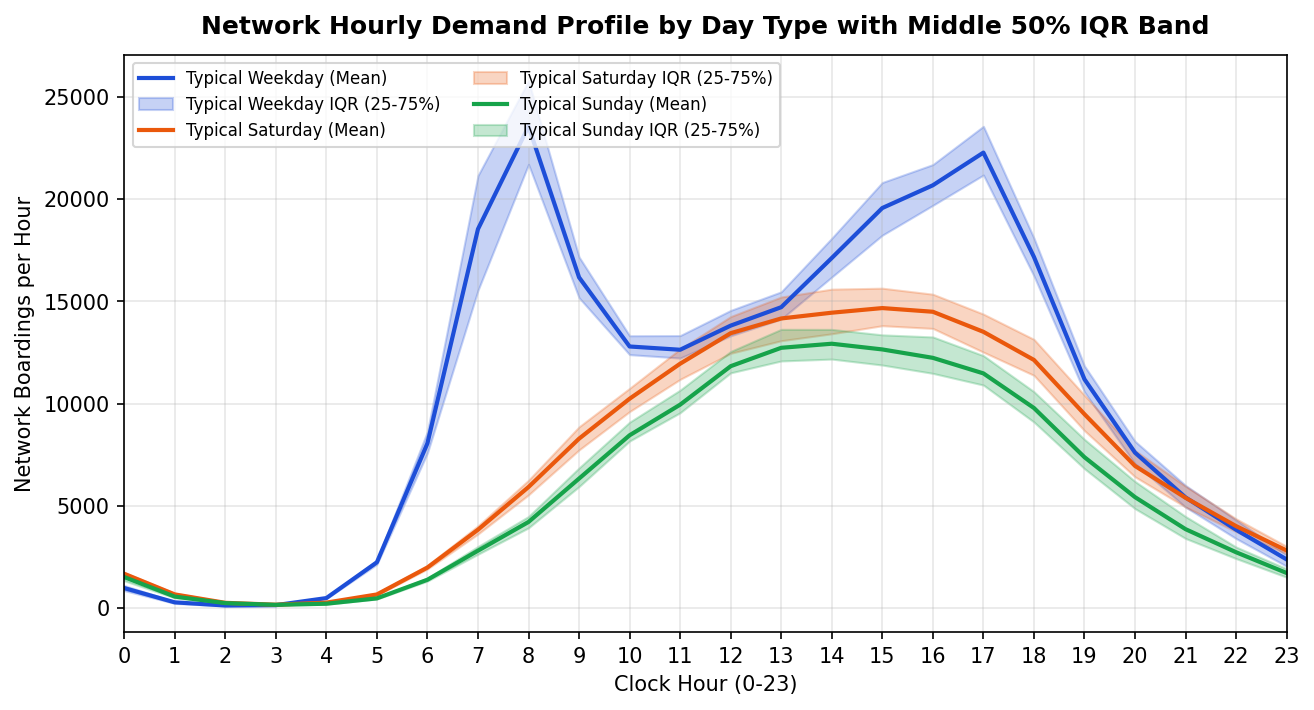

In [4]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

for d_name, d_sub in [('Typical Weekday', wd_typical), ('Typical Saturday', sat_typical), ('Typical Sunday', sun_typical)]:
    color = DAY_TYPE_COLORS['weekday' if 'Weekday' in d_name else 'saturday' if 'Saturday' in d_name else 'sunday']
    # Total network riders per date and hour
    h_date = d_sub.groupby(['date', 'hour'])['ridership'].sum().reset_index()
    stats = h_date.groupby('hour')['ridership'].agg(
        mean='mean',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75)
    ).reset_index()
    
    ax.plot(stats['hour'], stats['mean'], color=color, linewidth=2.0, label=f'{d_name} (Mean)')
    ax.fill_between(stats['hour'], stats['q25'], stats['q75'], color=color, alpha=0.25, label=f'{d_name} IQR (25-75%)')

ax.set_title('Network Hourly Demand Profile by Day Type with Middle 50% IQR Band', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Clock Hour (0-23)', fontsize=10)
ax.set_ylabel('Network Boardings per Hour', fontsize=10)
ax.set_xticks(range(24))
ax.set_xlim(0, 23)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=8, ncol=2)
fig.savefig(FIG / 'weekday_hourly_curve.png', dpi=150, bbox_inches='tight')
fig.savefig(FIG / 'm2_network_hourly_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 3.3: Weekday Riders by Month (Summer Dip & September Rebound)
Shows the average daily weekday boardings by month, illustrating the summer vacation trough.

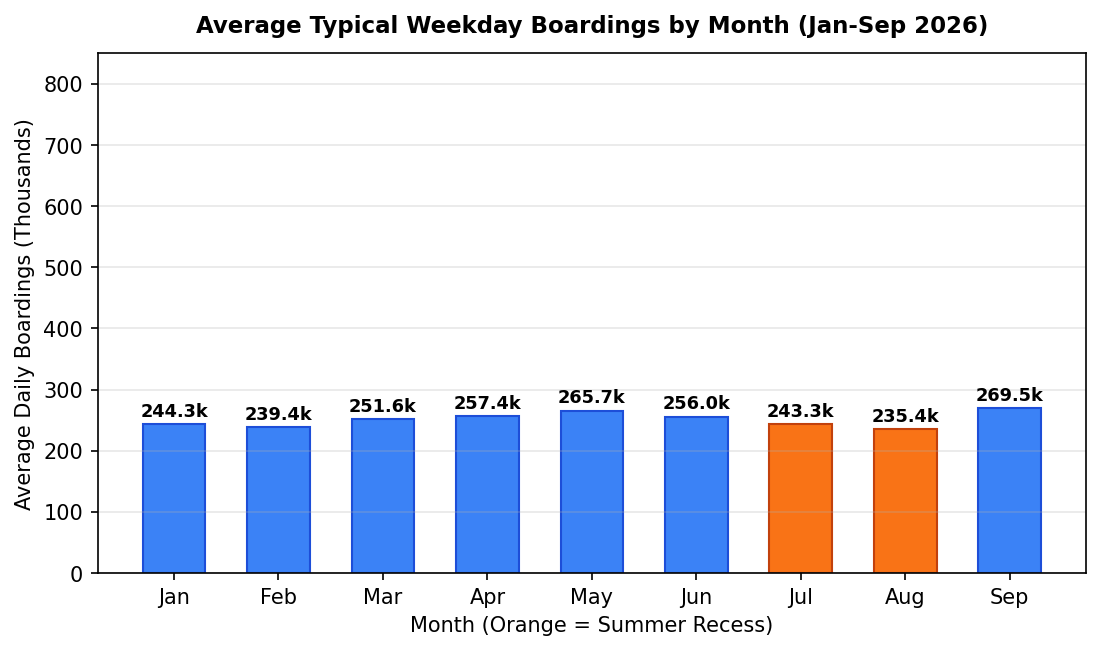

In [5]:
monthly = wd_typical.groupby(['month', 'date'])['ridership'].sum().groupby('month').agg(
    mean_daily='mean',
    days_count='count'
).reset_index()

month_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep'}
monthly['month_name'] = monthly['month'].map(month_map)

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=150)
bars = ax.bar(monthly['month_name'], monthly['mean_daily'] / 1000.0, color='#3b82f6', width=0.6, edgecolor='#1d4ed8')
# Highlight July & August
bars[6].set_facecolor('#f97316'); bars[6].set_edgecolor('#c2410c')
bars[7].set_facecolor('#f97316'); bars[7].set_edgecolor('#c2410c')

for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2.0, h + 6, f'{h:.1f}k', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_title('Average Typical Weekday Boardings by Month (Jan-Sep 2026)', fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel('Average Daily Boardings (Thousands)', fontsize=10)
ax.set_xlabel('Month (Orange = Summer Recess)', fontsize=10)
ax.set_ylim(0, 850)
ax.grid(axis='y', alpha=0.3)
fig.savefig(FIG / 'm2_network_monthly_ridership.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 3.4: The 10 Busiest Network Hours on Typical Weekdays
Ranked by average network boardings per clock hour.

In [6]:
top10_clock = pd.read_csv(TAB / 'm2_top_10_busiest_clock_hours.csv')
print('Top 10 Busiest Clock Hours across 180 Typical Weekdays:')
top10_clock.head(10)

Top 10 Busiest Clock Hours across 180 Typical Weekdays:


,rank,hour,avg_hourly_riders,avg_riders_formatted
0,1,8,23565.950000,"23,566.0"
1,2,17,22280.472222,"22,280.5"
2,3,16,20682.522222,"20,682.5"
3,4,15,19570.472222,"19,570.5"
4,5,7,18538.877778,"18,538.9"
5,6,18,17178.955556,"17,179.0"
6,7,14,17126.250000,"17,126.2"
7,8,9,16179.311111,"16,179.3"
8,9,13,14719.877778,"14,719.9"
9,10,12,13818.700000,"13,818.7"
